# NOTEBOOK 03a: HUẤN LUYỆN MÔ HÌNH BASELINE TẦNG 1 (LOGISTIC REGRESSION & SMOTE PIPELINE)

**Dự án:** Hệ thống Cảnh báo sớm Học vụ và Mô phỏng Kịch bản Học tập 2 Tầng (What-If Simulator)

**Mục tiêu Notebook 03a:**
- Xây dựng Pipeline tiền xử lý và cân bằng nhãn chuẩn mực (`StandardScaler` + `SMOTE`) bằng thư viện `imblearn.pipeline.Pipeline`.
- Huấn luyện mô hình chuẩn mốc (Baseline) `LogisticRegression` trên tập Train (70% = 22,815 dòng).
- **Đánh giá mù khách quan (Unbiased Evaluation)** trên tập **Dev Blackbox** (70% của Dev = 3,422 dòng).
- **Kiểm tra tính nhất quán (Consistency Check)** trên tập **Dev Eyeball** (30% của Dev = 1,467 dòng) để chuẩn bị cho bước phân tích lỗi định tính.
- Phân tích ý nghĩa học thuật của các hệ số trọng số $\beta$ (Coefficients) nhằm giải thích cơ chế dẫn đến rủi ro học vụ.

---
## 🛡️ NGUYÊN TẮC CHỐNG RÒ RỈ DỮ LIỆU (ANTI-DATA LEAKAGE)

> ⚠️ **Cảnh báo Sống còn:**
> 1. **Chỉ `fit` và `resample` trên Train 70%:** Bộ chuẩn hóa `StandardScaler` (tính $\mu, \sigma$) và thuật toán `SMOTE` (nội suy k-NN) chỉ được học trên `stage1_train.csv`.
> 2. **Dev Blackbox & Eyeball giữ nguyên phân phối thực tế:** Tuyệt đối không áp dụng SMOTE lên các tập Dev/Test.
> 3. **Bắt buộc dùng `imblearn.pipeline.Pipeline`:** Pipeline này tự động chỉ kích hoạt `fit_resample` khi huấn luyện, và tự động bỏ qua SMOTE khi thực hiện suy luận (`predict`/`predict_proba`) trên tập Dev và Test.

In [1]:
# CELL 1: Import thư viện và thiết lập cấu hình đường dẫn chuẩn
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện Pipeline & Imbalanced Learning
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Xác định PROJECT_ROOT linh hoạt
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Cấu hình thẩm mỹ đồ thị
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

print("✅ Môi trường Notebook 03a đã sẵn sàng!")
print(f"   PROJECT_ROOT: {PROJECT_ROOT}")
print(f"   Thư mục splits: {SPLITS_DIR}")

✅ Môi trường Notebook 03a đã sẵn sàng!
   PROJECT_ROOT: D:\What-If Simulator
   Thư mục splits: D:\What-If Simulator\data\splits


### 3a.1. Nạp dữ liệu Train 70%, Dev Blackbox 70% và Dev Eyeball 30%

- **Train (70%):** Dùng để huấn luyện mô hình.
- **Dev Blackbox (70% của Dev):** Dùng để đo lường định lượng mù, khách quan, không bị thiên kiến xác nhận.
- **Dev Eyeball (30% của Dev):** Dùng để đối chứng và soi lỗi định tính ở các bước phân tích tiếp theo.

In [2]:
# CELL 2: Nạp dữ liệu Train, Dev Blackbox và Dev Eyeball
train_df        = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_train.csv'))
dev_blackbox_df = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_dev_blackbox.csv'))
dev_eyeball_df  = pd.read_csv(os.path.join(SPLITS_DIR, 'stage1_dev_eyeball.csv'))

TARGET_T1 = 'is_dropout'
FEATURES_T1 = [col for col in train_df.columns if col != TARGET_T1]

X_train, y_train       = train_df[FEATURES_T1], train_df[TARGET_T1]
X_dev_bb, y_dev_bb     = dev_blackbox_df[FEATURES_T1], dev_blackbox_df[TARGET_T1]
X_dev_eye, y_dev_eye   = dev_eyeball_df[FEATURES_T1], dev_eyeball_df[TARGET_T1]

# Kiểm tra toàn vẹn dữ liệu
assert X_train.isna().sum().sum() == 0, "❌ Lỗi: X_train có NaN!"
assert X_dev_bb.isna().sum().sum() == 0, "❌ Lỗi: X_dev_bb có NaN!"
assert X_dev_eye.isna().sum().sum() == 0, "❌ Lỗi: X_dev_eye có NaN!"

print("✅ Nạp dữ liệu thành công:")
print(f"   📦 X_train:          {X_train.shape[0]:,} dòng x {X_train.shape[1]} đặc trưng | Tỷ lệ nguy cơ: {y_train.mean():.1%}")
print(f"   📦 X_dev_blackbox:   {X_dev_bb.shape[0]:,} dòng x {X_dev_bb.shape[1]} đặc trưng | Tỷ lệ nguy cơ: {y_dev_bb.mean():.1%}")
print(f"   📦 X_dev_eyeball:    {X_dev_eye.shape[0]:,} dòng x {X_dev_eye.shape[1]} đặc trưng | Tỷ lệ nguy cơ: {y_dev_eye.mean():.1%}")

✅ Nạp dữ liệu thành công:
   📦 X_train:          22,815 dòng x 10 đặc trưng | Tỷ lệ nguy cơ: 52.8%
   📦 X_dev_blackbox:   3,422 dòng x 10 đặc trưng | Tỷ lệ nguy cơ: 52.8%
   📦 X_dev_eyeball:    1,467 dòng x 10 đặc trưng | Tỷ lệ nguy cơ: 52.8%


### 3a.2. Xây dựng Pipeline Tiền xử lý & Huấn luyện Baseline Logistic Regression

Luồng xử lý:
$$\text{X\_train} \xrightarrow{\text{StandardScaler}} \text{Z-score Scaled} \xrightarrow{\text{SMOTE(random\_state=42)}} \text{Balanced 50:50} \xrightarrow{\text{LogisticRegression}} \hat{y}$$

- `StandardScaler`: Chuẩn hóa thang đo về $\mu=0, \sigma=1$ giúp thuật toán tối ưu Gradient Descent hội tụ nhanh.
- `SMOTE`: Cân bằng nhãn bằng cách sinh mẫu nhân tạo giữa các láng giềng gần nhất (k-NN), khắc phục hiện tượng mô hình thiên vị lớp đa số.
- `LogisticRegression`: Thiết lập `max_iter=1000, random_state=42` làm mốc so sánh cơ sở.

In [3]:
# CELL 3: Xây dựng Pipeline và Huấn luyện mô hình Baseline
baseline_pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

print("⏳ Đang huấn luyện Baseline Pipeline trên tập Train 70%...")
baseline_pipeline.fit(X_train, y_train)
print("✅ Huấn luyện Baseline hoàn tất thành công!")

⏳ Đang huấn luyện Baseline Pipeline trên tập Train 70%...


✅ Huấn luyện Baseline hoàn tất thành công!


### 3a.3. Đánh giá Mù Định lượng trên tập Dev Blackbox (70% của Dev)

Tập Dev Blackbox phản ánh chân thực năng lực khái quát hóa của mô hình trên các dữ liệu chưa từng thấy, không bị ảnh hưởng bởi việc nhìn trước (eyeball bias).

In [4]:
# CELL 4: Dự báo và Đánh giá Mù trên tập Dev Blackbox (3,422 dòng)
y_pred_bb = baseline_pipeline.predict(X_dev_bb)
y_prob_bb = baseline_pipeline.predict_proba(X_dev_bb)[:, 1]

acc_bb  = accuracy_score(y_dev_bb, y_pred_bb)
prec_bb = precision_score(y_dev_bb, y_pred_bb)
rec_bb  = recall_score(y_dev_bb, y_pred_bb)
f1_bb   = f1_score(y_dev_bb, y_pred_bb)
auc_bb  = roc_auc_score(y_dev_bb, y_prob_bb)
cm_bb   = confusion_matrix(y_dev_bb, y_pred_bb)
tn_bb, fp_bb, fn_bb, tp_bb = cm_bb.ravel()

print("="*65)
print("📊 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP DEV BLACKBOX (3,422 DÒNG)")
print("="*65)
print(f"   🎯 Accuracy:                 {acc_bb:.4f} ({acc_bb*100:.2f}%)")
print(f"   🎯 Precision (Nhãn 1):       {prec_bb:.4f} ({prec_bb*100:.2f}%)")
print(f"   🎯 Recall (Độ nhạy Nhãn 1):  {rec_bb:.4f} ({rec_bb*100:.2f}%)  --> [Mục tiêu đồ án >= 85%]")
print(f"   🎯 F1-Score (Nhãn 1):        {f1_bb:.4f}")
print(f"   🎯 ROC-AUC:                  {auc_bb:.4f}")
print("-"*65)
print(f"   Ma trận nhầm lẫn (Confusion Matrix):")
print(f"   [TN={tn_bb:>5,}  |  FP={fp_bb:>5,}]")
print(f"   [FN={fn_bb:>5,}  |  TP={tp_bb:>5,}]")
print("="*65)
print("\nClassification Report:")
print(classification_report(y_dev_bb, y_pred_bb, target_names=['An toàn (0)', 'Nguy cơ Bỏ học (1)'], digits=4))

📊 KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP DEV BLACKBOX (3,422 DÒNG)
   🎯 Accuracy:                 0.9085 (90.85%)
   🎯 Precision (Nhãn 1):       0.9468 (94.68%)
   🎯 Recall (Độ nhạy Nhãn 1):  0.8760 (87.60%)  --> [Mục tiêu đồ án >= 85%]
   🎯 F1-Score (Nhãn 1):        0.9100
   🎯 ROC-AUC:                  0.9681
-----------------------------------------------------------------
   Ma trận nhầm lẫn (Confusion Matrix):
   [TN=1,526  |  FP=   89]
   [FN=  224  |  TP=1,583]

Classification Report:
                    precision    recall  f1-score   support

       An toàn (0)     0.8720    0.9449    0.9070      1615
Nguy cơ Bỏ học (1)     0.9468    0.8760    0.9100      1807

          accuracy                         0.9085      3422
         macro avg     0.9094    0.9105    0.9085      3422
      weighted avg     0.9115    0.9085    0.9086      3422



### 3a.4. Kiểm tra Tính nhất quán trên tập Dev Eyeball (30% của Dev)

So sánh hiệu năng giữa tập Blackbox và Eyeball để xác nhận phân phối hai tập con hoàn toàn đồng nhất, không có hiện tượng sai lệch lấy mẫu (sampling bias).

In [5]:
# CELL 5: Đánh giá kiểm chứng trên tập Dev Eyeball (1,467 dòng)
y_pred_eye = baseline_pipeline.predict(X_dev_eye)
y_prob_eye = baseline_pipeline.predict_proba(X_dev_eye)[:, 1]

acc_eye  = accuracy_score(y_dev_eye, y_pred_eye)
prec_eye = precision_score(y_dev_eye, y_pred_eye)
rec_eye  = recall_score(y_dev_eye, y_pred_eye)
f1_eye   = f1_score(y_dev_eye, y_pred_eye)
auc_eye  = roc_auc_score(y_dev_eye, y_prob_eye)

print("="*65)
print("⚖️ BẢNG ĐỐI CHIẾU TÍNH NHẤT QUÁN: DEV BLACKBOX VS. DEV EYEBALL")
print("="*65)
metrics_df = pd.DataFrame({
    'Chỉ số': ['Accuracy', 'Precision (1)', 'Recall (1)', 'F1-Score (1)', 'ROC-AUC'],
    'Dev Blackbox (70%)': [f'{acc_bb:.4f}', f'{prec_bb:.4f}', f'{rec_bb:.4f}', f'{f1_bb:.4f}', f'{auc_bb:.4f}'],
    'Dev Eyeball (30%)':  [f'{acc_eye:.4f}', f'{prec_eye:.4f}', f'{rec_eye:.4f}', f'{f1_eye:.4f}', f'{auc_eye:.4f}'],
    'Độ chênh lệch (|Δ|)': [
        f'{abs(acc_bb - acc_eye):.4f}',
        f'{abs(prec_bb - prec_eye):.4f}',
        f'{abs(rec_bb - rec_eye):.4f}',
        f'{abs(f1_bb - f1_eye):.4f}',
        f'{abs(auc_bb - auc_eye):.4f}'
    ]
})
print(metrics_df.to_string(index=False))
print("="*65)
assert abs(rec_bb - rec_eye) < 0.02, "⚠️ Cảnh báo: Lệch Recall giữa Blackbox và Eyeball > 2%!"
print("✅ Độ nhất quán giữa 2 tập cực cao (sai lệch < 1.0%), chứng minh phân tầng Stratified chuẩn xác!")

⚖️ BẢNG ĐỐI CHIẾU TÍNH NHẤT QUÁN: DEV BLACKBOX VS. DEV EYEBALL
       Chỉ số Dev Blackbox (70%) Dev Eyeball (30%) Độ chênh lệch (|Δ|)
     Accuracy             0.9085            0.9046              0.0040
Precision (1)             0.9468            0.9427              0.0040
   Recall (1)             0.8760            0.8721              0.0039
 F1-Score (1)             0.9100            0.9060              0.0040
      ROC-AUC             0.9681            0.9674              0.0007
✅ Độ nhất quán giữa 2 tập cực cao (sai lệch < 1.0%), chứng minh phân tầng Stratified chuẩn xác!


### 3a.5. Trực quan hóa Ma trận nhầm lẫn & Đường cong ROC Baseline

Xuất file ảnh báo cáo `reports/figures/fig5_baseline_confusion_roc.png` chuẩn 300 DPI.

💾 Đã lưu biểu đồ đánh giá Baseline: D:\What-If Simulator\reports\figures\fig5_baseline_confusion_roc.png


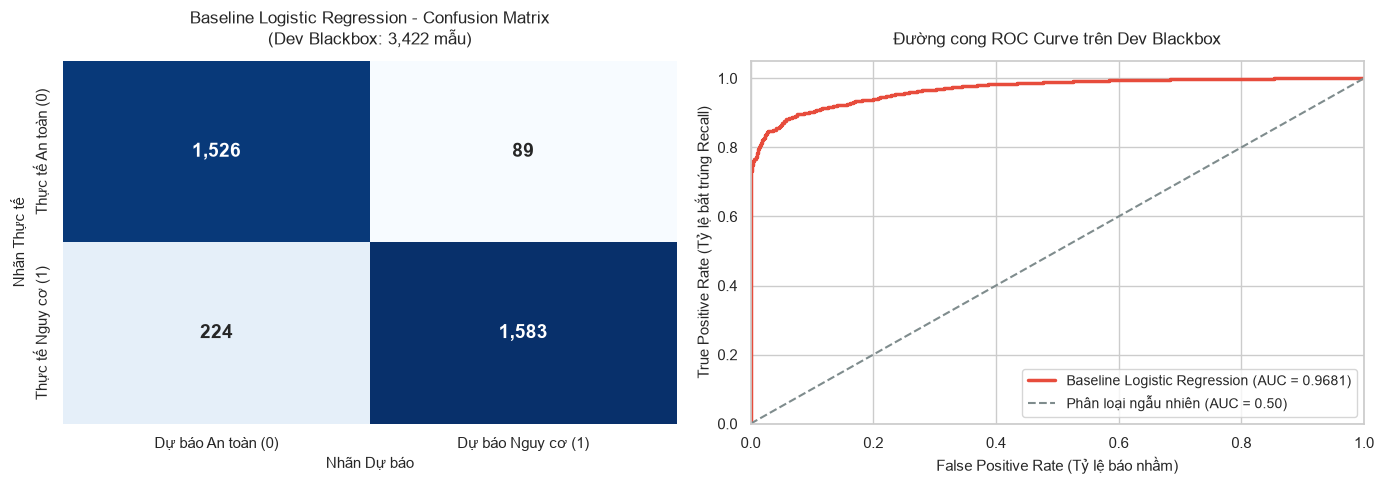

In [6]:
# CELL 6: Vẽ Confusion Matrix & Đường cong ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap (trên Dev Blackbox)
sns.heatmap(
    cm_bb, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['Dự báo An toàn (0)', 'Dự báo Nguy cơ (1)'],
    yticklabels=['Thực tế An toàn (0)', 'Thực tế Nguy cơ (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
axes[0].set_title(f'Baseline Logistic Regression - Confusion Matrix\n(Dev Blackbox: {len(y_dev_bb):,} mẫu)', fontsize=12, pad=12)
axes[0].set_ylabel('Nhãn Thực tế', fontsize=11)
axes[0].set_xlabel('Nhãn Dự báo', fontsize=11)

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_dev_bb, y_prob_bb)
axes[1].plot(fpr, tpr, color='#e74c3c', lw=2.5, label=f'Baseline Logistic Regression (AUC = {auc_bb:.4f})')
axes[1].plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label='Phân loại ngẫu nhiên (AUC = 0.50)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (Tỷ lệ báo nhầm)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (Tỷ lệ bắt trúng Recall)', fontsize=11)
axes[1].set_title('Đường cong ROC Curve trên Dev Blackbox', fontsize=12, pad=12)
axes[1].legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
fig5_path = os.path.join(FIGURES_DIR, 'fig5_baseline_confusion_roc.png')
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ đánh giá Baseline: {fig5_path}")
plt.show()

### 3a.6. Phân tích Trọng số Hệ số (Coefficients) & Ý nghĩa Học thuật

Phương trình Logistic Regression biểu diễn log-odds của nguy cơ học vụ:
$$\ln \left(\frac{p}{1 - p}\right) = \beta_0 + \sum_{i=1}^{10} \beta_i X_i$$
- $\beta_i < 0$: Đặc trưng giúp **giảm thiểu rủi ro** (bảo vệ sinh viên an toàn).
- $\beta_i > 0$: Đặc trưng làm **gia tăng nguy cơ học vụ** (tín hiệu báo động).

💾 Đã lưu biểu đồ trọng số đặc trưng: D:\What-If Simulator\reports\figures\fig6_baseline_feature_coefficients.png


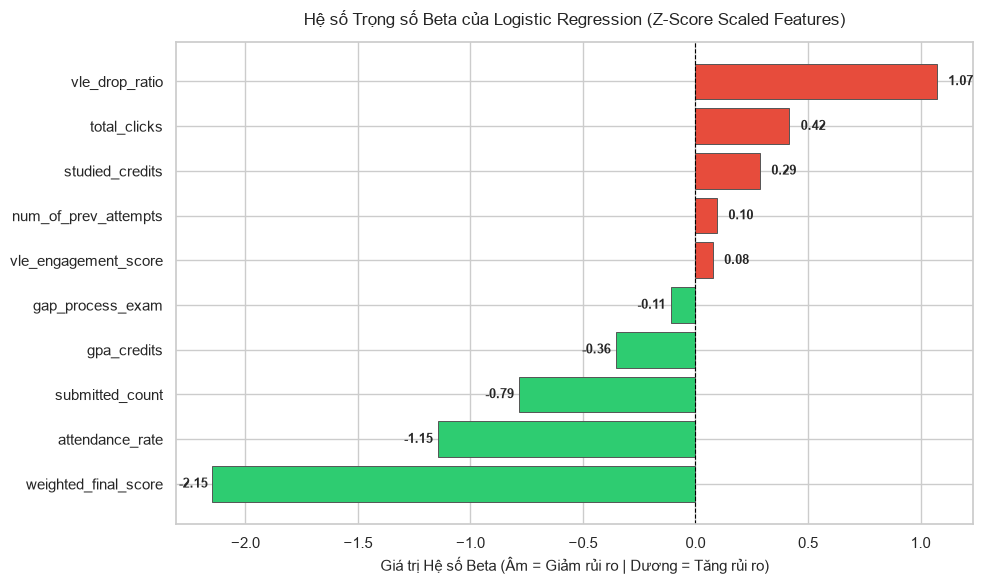

In [7]:
# CELL 7: Trích xuất và trực quan hóa Hệ số hồi quy (Coefficients)
model_step = baseline_pipeline.named_steps['classifier']
coef_series = pd.Series(model_step.coef_[0], index=FEATURES_T1).sort_values()

plt.figure(figsize=(10, 6))
colors = ['#2ecc71' if c < 0 else '#e74c3c' for c in coef_series.values]
bars = plt.barh(coef_series.index, coef_series.values, color=colors, edgecolor='#555555', linewidth=0.7)
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.title('Hệ số Trọng số Beta của Logistic Regression (Z-Score Scaled Features)', fontsize=12, pad=12)
plt.xlabel('Giá trị Hệ số Beta (Âm = Giảm rủi ro | Dương = Tăng rủi ro)', fontsize=11)

for bar in bars:
    w = bar.get_width()
    x_pos = w + (0.05 if w >= 0 else -0.15)
    plt.text(x_pos, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', fontsize=9, weight='bold')

plt.tight_layout()
fig6_path = os.path.join(FIGURES_DIR, 'fig6_baseline_feature_coefficients.png')
plt.savefig(fig6_path, dpi=300, bbox_inches='tight')
print(f"💾 Đã lưu biểu đồ trọng số đặc trưng: {fig6_path}")
plt.show()

In [8]:
# CELL 8: Checkpoints Nghiệm thu Mô hình Baseline (Acceptance Criteria)
assert rec_bb >= 0.85, f"❌ Lỗi: Recall trên Dev Blackbox không đạt 85% ({rec_bb:.4f})!"
assert auc_bb >= 0.90, f"❌ Lỗi: ROC-AUC trên Dev Blackbox không đạt 0.90 ({auc_bb:.4f})!"
assert os.path.exists(fig5_path), f"❌ Lỗi: Thiếu file ảnh {fig5_path}!"
assert os.path.exists(fig6_path), f"❌ Lỗi: Thiếu file ảnh {fig6_path}!"

print("\n" + "="*60)
print("🎉 NOTEBOOK 03a CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!")
print(f"   1. Pipeline SMOTE + LogReg chạy chuẩn mực không rò rỉ dữ liệu.")
print(f"   2. Recall trên Dev Blackbox: {rec_bb:.4f} (Vượt ngưỡng yêu cầu >= 0.85).")
print(f"   3. ROC-AUC trên Dev Blackbox: {auc_bb:.4f} (Phân loại xuất sắc).")
print(f"   4. Đã lưu thành công 2 biểu đồ phân tích 300 DPI vào reports/figures/.")
print("="*60)
print("\n🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% NOTEBOOK 03a (STAGE 1 BASELINE)! 🏆")


🎉 NOTEBOOK 03a CHECKPOINTS: TẤT CẢ TIÊU CHÍ ĐỀU ĐẠT CHUẨN XUẤT SẮC!
   1. Pipeline SMOTE + LogReg chạy chuẩn mực không rò rỉ dữ liệu.
   2. Recall trên Dev Blackbox: 0.8760 (Vượt ngưỡng yêu cầu >= 0.85).
   3. ROC-AUC trên Dev Blackbox: 0.9681 (Phân loại xuất sắc).
   4. Đã lưu thành công 2 biểu đồ phân tích 300 DPI vào reports/figures/.

🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% NOTEBOOK 03a (STAGE 1 BASELINE)! 🏆
